# Grid Search Analysis: GRN Inference Performance (Detailed)
This notebook analyzes the performance metrics without aggregating over different parameter configurations.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set plotting style
sns.set_theme(style='whitegrid', context='talk')
os.makedirs('images/detailed', exist_ok=True)


In [2]:
# Load data
df = pd.read_csv('results/grid_results/performance_metrics.csv')
# We no longer drop duplicates because we want to keep all trials for seaborn to calculate confidence intervals
# df = df.drop_duplicates(subset=['dt_meas', 'M_pairs', 't_window_start', 't_window_end', 'N'], keep='last')

def label_window(row):
    if row['t_window_start'] == 0.0:
        return 'T'
    else:
        return 'S'
        
df['Regime'] = df.apply(label_window, axis=1)

# select rows where M <= 1000
df = df[df['M_pairs'] <= 1000]
df = df.reset_index(drop=True)

numeric_cols = ['TP', 'FP', 'FN', 'TN', 'TPR (Recall)', 'FPR', 'Precision', 'F1-Score', 'SHD']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [3]:
df.columns

Index(['trial', 'dt_meas', 'M_pairs', 't_window_start', 't_window_end', 'N',
       'm', 'Regime', 'TP', 'FP', 'FN', 'TN', 'TPR (Recall)', 'FPR',
       'Precision', 'F1-Score', 'SHD', 'AUROC', 'AUPRC', 'AUPRC_Ratio',
       'AUPRC_Norm', 'MSE', 'Pearson', 'Spearman', 'RBO', 'Wasserstein'],
      dtype='str')

In [ ]:
# Plot F1-Score vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='M_pairs', y='F1-Score', hue='N',
    col='dt_meas', row='Regime', kind='line', err_style='band', marker='o',
     height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.figure.suptitle('F1-Score vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Plot F1-Score vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='F1-Score', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='viridis', height=4, aspect=1.2
)

g.set(xscale='log')
g.figure.suptitle('F1-Score vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Plot TPR (Recall) vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='TPR (Recall)', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='magma', height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.set(xscale='log')
g.figure.suptitle('TPR (Recall) vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Plot FPR vs M_pairs. We use a FacetGrid to separate dt_meas (columns) and Regime (rows).
g = sns.relplot(
    data=df, x='dt_meas', y='FPR', hue='N',
    col='M_pairs', row='Regime', kind='line', err_style='band', marker='o',
    palette='coolwarm', height=4, aspect=1.2
)
#g.set(xlim=(0, 1100))
g.set(xscale='log')
g.figure.suptitle('FPR vs M_pairs for fixed dt_meas and Regime', y=1.05)
g.savefig('images/detailed/performance_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


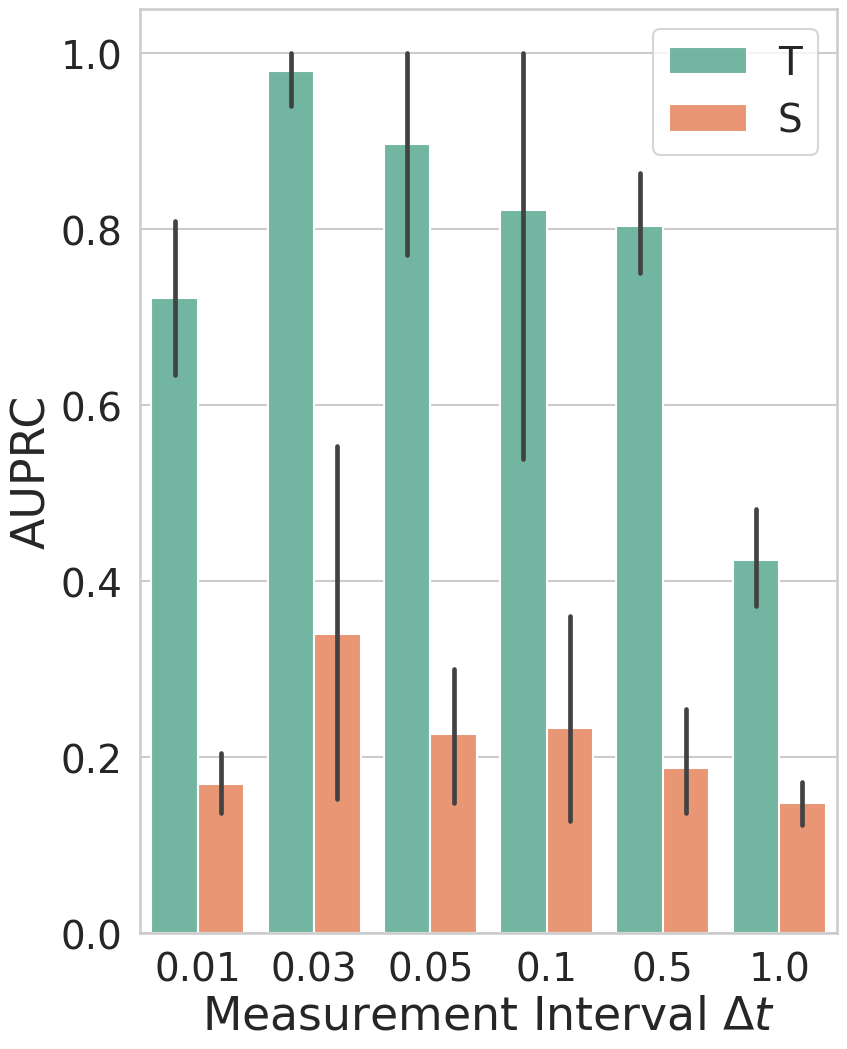

In [26]:
# Choose a specific configuration to compare transient vs stationary: M_pairs=500, dt_meas=0.05
fixed_M = 500
fixed_dt = 0.05
df_subset = df[(df['M_pairs'] == fixed_M) & (df['N'] == 10)]

fig, ax = plt.subplots(figsize=(9, 12))
fontsize = 28

sns.barplot(data=df_subset, x='dt_meas', y='AUPRC', hue='Regime', palette='Set2', ax=ax)
ax.set_xlabel(r'Measurement Interval $\Delta t$', fontsize=fontsize+5)
ax.set_ylabel('AUPRC', fontsize=fontsize+5)
ax.tick_params(axis='both', which='major', labelsize=fontsize)

plt.legend(loc='upper right', fontsize=fontsize)
plt.savefig('images/detailed/transient_vs_stationary_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Choose a specific configuration to compare transient vs stationary: M_pairs=500, dt_meas=0.05
fixed_M = 500
fixed_dt = 0.05
df_subset = df[(df['M_pairs'] == fixed_M) & (df['dt_meas'] == fixed_dt)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=df_subset, x='N', y='AUPRC', hue='Regime', palette='Set2', ax=ax)
ax.set_title(f'AUPRC: Transient vs Stationary (Fixed M={fixed_M}, dt={fixed_dt})')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/transient_vs_stationary_AUPRC_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


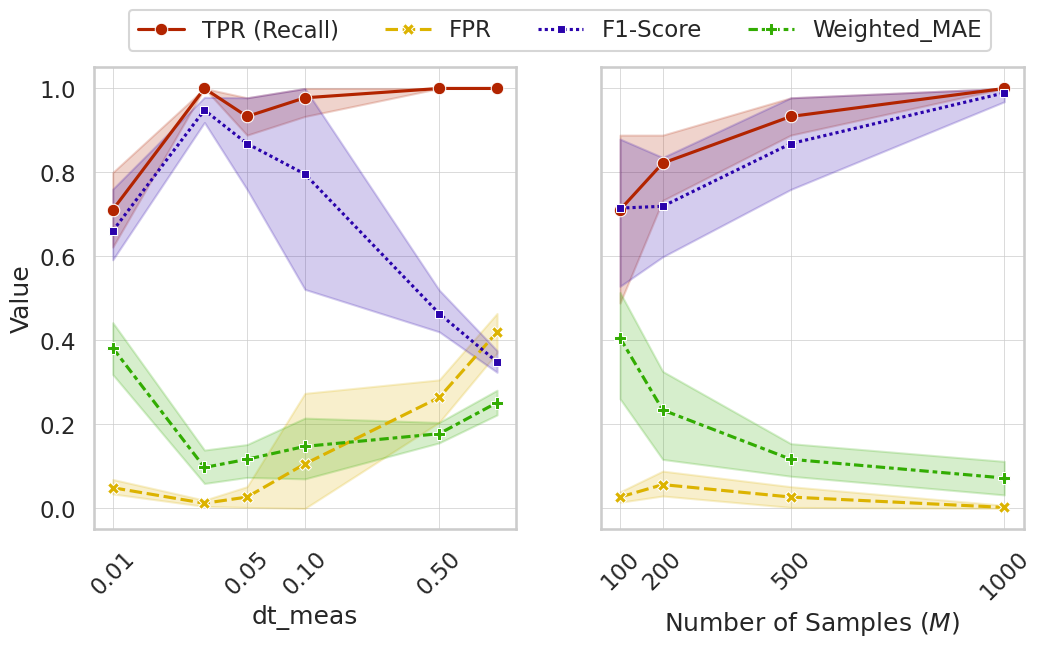

In [17]:
# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['M_pairs'] == 500) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Include MAE in the comparison
df_melted = df_dt.melt(
    id_vars=['dt_meas'],
    value_vars=['TPR (Recall)', 'FPR', 'F1-Score', 'Weighted_MAE'],
    var_name='Metric',
    value_name='Score'
)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

ax = axs[0]

sns.lineplot(
    data=df_melted, x='dt_meas', y='Score',
    hue='Metric', style='Metric',
    markers=True, err_style='band', ax=ax,
    palette=["#b22400", "#dcb300", "#2a03ac", "#32ac02"]
)

ax.set_xlabel('dt_meas')
ax.set_ylabel('Value')
ax.set_xscale('log')
ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax.tick_params(axis='x', rotation=45)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.grid(lw=0.5)
ax.legend(bbox_to_anchor=(2.15, 1.15), ncol=4)

# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['dt_meas'] == 0.05) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Include MAE in the comparison
df_melted = df_dt.melt(
    id_vars=['M_pairs'],
    value_vars=['TPR (Recall)', 'FPR', 'F1-Score', 'Weighted_MAE'],
    var_name='Metric',
    value_name='Score'
)

ax = axs[1]
sns.lineplot(
    data=df_melted, x='M_pairs', y='Score',
    hue='Metric', style='Metric',
    markers=True, err_style='band', ax=ax, legend=False,
    palette=["#b22400", "#dcb300", "#2a03ac", "#32ac02"]
)

ax.set_xlabel(r'Number of Samples ($M$)')
ax.set_ylabel('')
#ax.set_xscale('log')
ax.set_xticks([100, 200, 500, 1000])
ax.tick_params(axis='x', rotation=45)
ax.set_yticks(np.arange(0,1.1,0.2))
ax.set_yticklabels([])
ax.grid(lw=0.5)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
#ax.set_title(f'TPR, FPR, F1-Score, and MAE vs dt_meas (Fixed M={fixed_M}, Regime={fixed_Regime}, N={fixed_N})')
#plt.tight_layout()

plt.savefig('images/detailed/metrics_comparison_single_N.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Choose a specific configuration: M_pairs=500, Regime=Transient, N=10
fixed_Regime = 'T'
fixed_N = 10
df_dt = df[(df['dt_meas'] == 0.5) & (df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

# Include MAE in the comparison
df_melted = df_dt.melt(
    id_vars=['M_pairs'],
    value_vars=['TPR (Recall)', 'FPR', 'F1-Score', 'Weighted_MAE'],
    var_name='Metric',
    value_name='Score'
)

fig, ax = plt.subplots(figsize=(8, 9))
sns.lineplot(
    data=df_melted, x='M_pairs', y='Score',
    hue='Metric', style='Metric',
    markers=True, err_style='band', ax=ax
)

ax.set_xlabel(r'Number of Samples ($M$)')
ax.set_ylabel('Value')
#ax.set_xscale('log')
ax.set_xticks([100, 200, 500, 1000])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
#ax.set_title(f'TPR, FPR, F1-Score, and MAE vs dt_meas (Fixed M={fixed_M}, Regime={fixed_Regime}, N={fixed_N})')
ax.legend('')
plt.savefig('images/detailed/metrics_comparison_single_N.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# plot heatmpas of MAE vs dt_meas and M_pairs for fixed N and Regime
fixed_Regime = 'T'
fixed_N = 10
df_subset = df[(df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

plt.figure(figsize=(10, 6))
heatmap_data = df_subset.pivot_table(index='M_pairs', columns='dt_meas', values='Weighted_MAE')
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='viridis', cbar_kws={'label': 'Weighted MAE'})
plt.title(f'Heatmap of Weighted MAE vs dt_meas and M_pairs (Fixed Regime={fixed_Regime}, N={fixed_N})')
plt.xlabel('dt_meas')
plt.ylabel('M_pairs')
plt.savefig('images/detailed/heatmap_MAE.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Choose a specific configuration: M_pairs=500, Regime=Transient
fixed_Regime = 'T'
df_dt = df[(df['M_pairs'] == fixed_M) & (df['Regime'] == fixed_Regime)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(err_style='bars', err_kws={'capsize': 3}, data=df_dt, x='dt_meas', y='FPR', hue='N', marker='s', palette='coolwarm', ax=ax)
ax.set_title(f'Impact of dt_meas on F1-Score (Fixed M={fixed_M}, Regime={fixed_Regime})')
ax.set_xscale('log')
ax.set_xticks([0.01, 0.05, 0.1, 0.5])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('images/detailed/impact_of_dt_fixed.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# Plot SHD vs N, faceted by Regime and dt_meas, for fixed M_pairs=500
g = sns.catplot(
    data=df[df['M_pairs'] == fixed_M], x='N', y='SHD', 
    hue='Regime', col='dt_meas', kind='bar',
    palette='muted', height=5, aspect=0.8
)
g.fig.suptitle(f'Structural Hamming Distance for fixed M={fixed_M}', y=1.05)
g.savefig('images/detailed/shd_faceted.png', dpi=300, bbox_inches='tight')
plt.show()


## Weighted Network Error (MAE)
Let's evaluate the mean absolute distance between the inferred and true non-zero edge weights.

In [ ]:
df['Weighted_MAE'] = pd.to_numeric(df['Weighted_MAE'], errors='coerce')

g = sns.catplot(
    data=df, 
    x="M_pairs", y="Weighted_MAE", hue="Regime", col="dt_meas", 
    col_wrap=3, kind="point", height=4, aspect=1.2, capsize=.1,
    palette={"T": "orange", "S": "blue"}, markers=["o", "s"], linestyles=["-", "--"]
)
g.set_axis_labels("Number of Samples (M)", "Mean Absolute Error (MAE)")
g.set_titles(r"$\Delta t$ = {col_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Weighted MAE vs M_pairs across dt_meas (Lower is Better)')
plt.savefig('images/detailed/Weighted_MAE_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
df['Weighted_MAE'] = pd.to_numeric(df['Weighted_MAE'], errors='coerce')

g = sns.catplot(
    data=df, 
    x="dt_meas", y="Weighted_MAE", hue="Regime", col="M_pairs", 
    col_wrap=3, kind="point", height=4, aspect=1.2, capsize=.1,
    palette={"T": "orange", "S": "blue"}, markers=["o", "s"], linestyles=["-", "--"]
)
g.set_axis_labels("Time Interval (dt)", "Mean Absolute Error (MAE)")
g.set_titles(r"M = {col_name}")
plt.subplots_adjust(top=0.9)
g.fig.suptitle('Weighted MAE vs M_pairs across dt_meas (Lower is Better)')
plt.savefig('images/detailed/Weighted_MAE_vs_M_faceted.png', dpi=300, bbox_inches='tight')
plt.show()

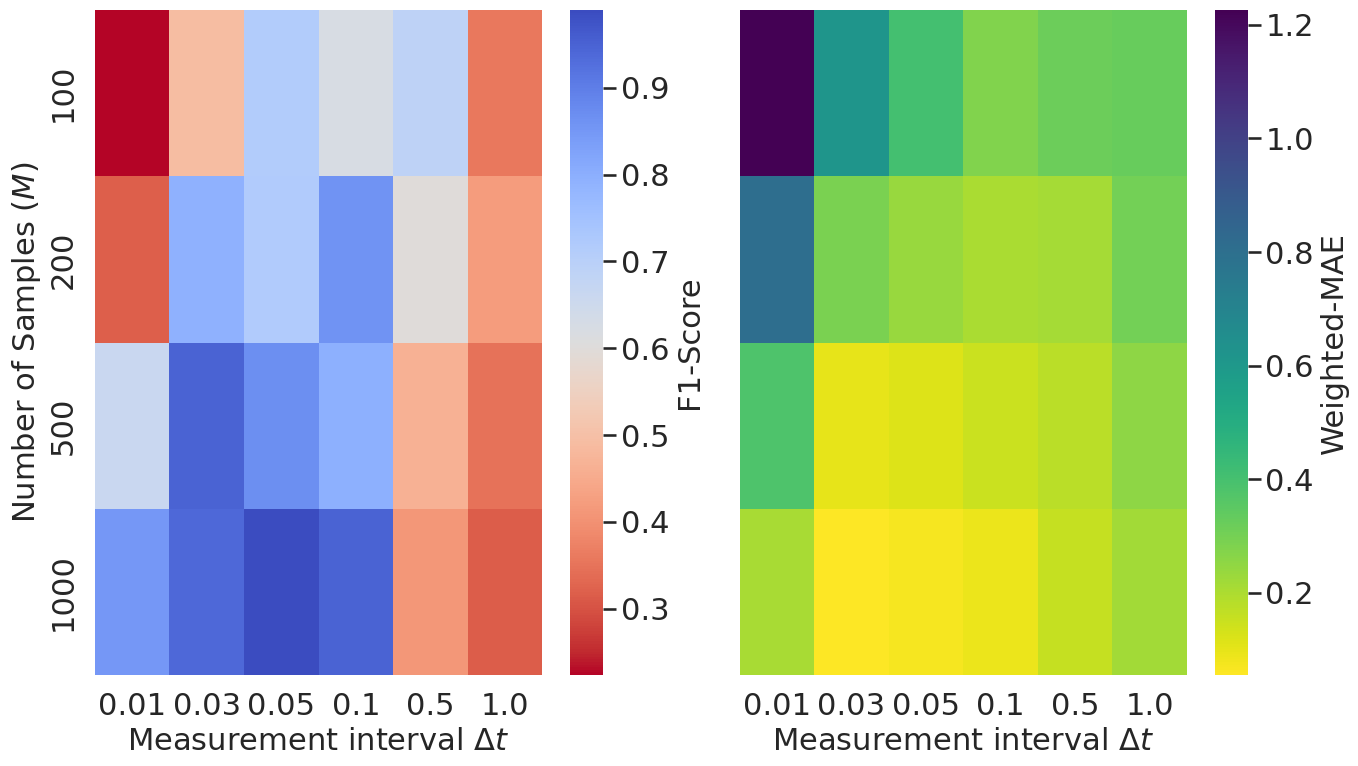

In [22]:
# plot heatmpas of MAE vs dt_meas and M_pairs for fixed N and Regime
fixed_Regime = 'T'
fixed_N = 10
df_subset = df[(df['Regime'] == fixed_Regime) & (df['N'] == fixed_N)]

fig, axs = plt.subplots(1,2,figsize=(14, 8))
fontsize=22

ax = axs[0]
heatmap_data = df_subset.pivot_table(index='M_pairs', columns='dt_meas', values='F1-Score')
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap='coolwarm_r', cbar_kws={'label': 'F1-Score'}, ax=ax)
ax.collections[0].colorbar.ax.tick_params(labelsize=fontsize)
ax.collections[0].colorbar.set_label('F1-Score', fontsize=fontsize)
#plt.title(f'Heatmap of Weighted MAE vs dt_meas and M_pairs (Fixed Regime={fixed_Regime}, N={fixed_N})')
ax.set_xlabel(r'Measurement interval $\Delta t$', fontsize=fontsize)
ax.set_ylabel(r'Number of Samples ($M$)', fontsize=fontsize)
ax.tick_params(which='both', labelsize=fontsize)

ax = axs[1]
heatmap_data = df_subset.pivot_table(index='M_pairs', columns='dt_meas', values='Weighted_MAE')
sns.heatmap(heatmap_data, annot=False, fmt=".2f", cmap='viridis_r', cbar_kws={'label': 'Weighted-MAE'}, ax=ax)
ax.collections[0].colorbar.ax.tick_params(labelsize=fontsize)
ax.collections[0].colorbar.set_label('Weighted-MAE', fontsize=fontsize)
#plt.title(f'Heatmap of Weighted MAE vs dt_meas and M_pairs (Fixed Regime={fixed_Regime}, N={fixed_N})')
ax.set_xlabel(r'Measurement interval $\Delta t$', fontsize=fontsize)
ax.set_ylabel('')
ax.set_yticklabels([])
ax.tick_params(which='both', labelsize=fontsize)

plt.tight_layout()

plt.show()